# Лабораторная работа №3: Foundation models для сегментации: SAM/SAM 2

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Получить маски по point и box prompts.
- Автоматически сформировать prompts из GT или детектора.
- Сравнить zero-shot и refinement head.


## Теоретическая часть

Promptable segmentation оценивает маску $M=f(I,p)$ по изображению и prompt $p$ (точка, box или маска). SAM разделяет тяжёлый image encoder и лёгкий prompt/mask decoder, поэтому один embedding изображения можно использовать для многих запросов.

![SAM architecture](https://raw.githubusercontent.com/facebookresearch/segment-anything/main/assets/model_diagram.png)


### Математическая постановка

Качество promptable-модели оценивают не только IoU, но и числом взаимодействий до достижения целевого качества: $N@IoU\geq\tau$. Для ускорения разметки важна доля масок, принимаемых без существенной коррекции.


### Материалы

- [Segment Anything](https://github.com/facebookresearch/segment-anything)
- [Transformers SAM docs](https://huggingface.co/docs/transformers/model_doc/sam)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Получить маски по point и box prompts.
2. Автоматически сформировать prompts из GT или детектора.
3. Сравнить zero-shot и refinement head.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** SAM ViT-B/MobileSAM inference, frozen encoder.
- **Ограничение данных:** до 200 изображений 512 px.
- **Fallback:** CPU на 20 изображениях или MobileSAM.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [ ]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


In [ ]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Загрузка SAM и отложенных масок

*Вес: 1 балл.*

**Постановка.** Сравнение prompts возможно лишь на одних размеченных изображениях.

Выполните следующие действия:
1. Загрузите pretrained SAM и test Oxford-IIIT Pet.
2. Зафиксируйте индексы проверки.

**Результат.** dataset_manifest.json и объекты processor, model, eval_ds.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 1. Загрузка SAM и отложенных масок ===
# pip install transformers>=4.40
import torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader, TensorDataset
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import transformers
from transformers import SamModel, SamProcessor

CFG = {"sam_checkpoint": "facebook/sam-vit-base", "n_eval": 8 if FAST_DEV_RUN else 200, "max_side": 512,
       "n_refine_train": 8 if FAST_DEV_RUN else 300, "refine_size": 256, "refine_epochs": 1 if FAST_DEV_RUN else 15,
       "sup_size": 128 if FAST_DEV_RUN else 256, "sup_epochs": 1 if FAST_DEV_RUN else 6, "batch_size": 8 if FAST_DEV_RUN else 16,
       "accept_iou": 0.9, "n_synthetic": 32}
(ARTIFACTS / "config.json").write_text(json.dumps({**CFG, "transformers": transformers.__version__, "torch": torch.__version__}, indent=2))

class SyntheticPets(Dataset):
    """Только для FAST_DEV_RUN без сети: trimap как у Oxford Pet (1=pet, 2=фон, 3=контур)."""
    def __init__(self, n, seed): self.n, self.seed = n, seed; self._labels = [0] * n
    def __len__(self): return self.n
    def __getitem__(self, i):
        r = np.random.default_rng(self.seed + i); w, h = 200, 160
        img = Image.fromarray((r.random((h, w, 3)) * 80).astype(np.uint8)); m = Image.new("L", (w, h), 2)
        rx, ry = r.integers(15, 80), r.integers(15, 60); cx, cy = r.integers(rx, w - rx), r.integers(ry, h - ry)
        box = [cx - rx, cy - ry, cx + rx, cy + ry]
        ImageDraw.Draw(img).ellipse(box, fill=tuple(int(v) for v in r.integers(120, 255, 3)))
        ImageDraw.Draw(m).ellipse(box, fill=1, outline=3, width=2)
        return img, m

def load_pets(split):
    try:
        return torchvision.datasets.OxfordIIITPet(DATA_ROOT, split=split, target_types="segmentation", download=True)
    except Exception as e:
        if not FAST_DEV_RUN: raise
        print(f"Oxford-IIIT Pet ({split}) недоступен, smoke-режим на синтетике:", type(e).__name__)
        return SyntheticPets(CFG["n_synthetic"], 0 if split == "trainval" else 10**6)

def binary_gt(trimap):
    """Объект = pet (1) + граничная полоса (3); фон = 2."""
    return np.array(trimap) != 2

def load_item(ds_, i, max_side=CFG["max_side"]):
    """RGB uint8 + бинарная GT-маска, длинная сторона ≤ 512 px (маска — NEAREST)."""
    img, tri = ds_[i]
    img = img.convert("RGB"); s = min(1.0, max_side / max(img.size))
    if s < 1:
        size = (round(img.size[0] * s), round(img.size[1] * s))
        img, tri = img.resize(size, Image.BILINEAR), tri.resize(size, Image.NEAREST)
    return np.array(img), binary_gt(tri)

# --- SAM ---
try:
    processor = SamProcessor.from_pretrained(CFG["sam_checkpoint"])
    model = SamModel.from_pretrained(CFG["sam_checkpoint"]).to(DEVICE).eval()
except Exception as e:
    if not FAST_DEV_RUN: raise
    print("SAM-веса недоступны, smoke-режим: маленькая случайная SAM той же архитектуры:", type(e).__name__)
    from transformers import SamConfig, SamImageProcessor
    from transformers.models.sam.configuration_sam import SamVisionConfig
    vc = SamVisionConfig(hidden_size=64, num_hidden_layers=2, num_attention_heads=2, global_attn_indexes=[1], mlp_dim=128)
    model = SamModel(SamConfig(vision_config=vc.to_dict())).to(DEVICE).eval()
    processor = SamProcessor(image_processor=SamImageProcessor())
for p in model.parameters(): p.requires_grad = False   # encoder и decoder заморожены — zero-shot

# --- фиксированная отложенная выборка test ---
test_pets = load_pets("test")
eval_indices = np.sort(np.random.default_rng(SEED).choice(len(test_pets), min(CFG["n_eval"], len(test_pets)), replace=False))
eval_ds = [load_item(test_pets, int(i)) for i in eval_indices]   # список (image, gt_mask)
manifest = {"dataset": "Oxford-IIIT Pet", "split": "test", "n_total": len(test_pets), "seed": SEED,
            "indices": eval_indices.tolist(), "gt_definition": "trimap != 2 (pet + border)", "max_side": CFG["max_side"],
            "files": [Path(test_pets._images[i]).name for i in eval_indices] if hasattr(test_pets, "_images") else None,
            "sam_checkpoint": CFG["sam_checkpoint"]}
json.dump(manifest, open(ARTIFACTS / "dataset_manifest.json", "w"), indent=2)
check(len(eval_ds) == len(eval_indices) and all(m.any() for _, m in eval_ds), "все отложенные изображения содержат объект")
print("eval images:", len(eval_ds), "| SAM params: %.1fM" % (sum(p.numel() for p in model.parameters()) / 1e6))

### Геометрия подсказок и IoU

*Вес: 1 балл.*

**Постановка.** Box и point должны воспроизводимо извлекаться из одной истинной маски.

Выполните следующие действия:
1. Реализуйте IoU масок и ограничивающий прямоугольник.
2. Документируйте, что подсказки из GT моделируют действия разметчика.

**Результат.** Функции iou и box_from_mask.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 2. Геометрия подсказок и IoU ===
def iou(a, b):
    a, b = np.asarray(a, bool), np.asarray(b, bool)
    union = np.logical_or(a, b).sum()
    return float(np.logical_and(a, b).sum() / union) if union > 0 else 1.0

def box_from_mask(mask):
    """Плотный ограничивающий прямоугольник [x0, y0, x1, y1] в пикселях исходного изображения."""
    ys, xs = np.nonzero(mask)
    return [int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())]

def point_from_mask(mask):
    """Положительная точка: покоординатная медиана пикселей объекта; если она вне объекта — ближайший пиксель объекта."""
    ys, xs = np.nonzero(mask)
    x, y = int(np.median(xs)), int(np.median(ys))
    if not mask[y, x]:
        k = np.argmin((xs - x) ** 2 + (ys - y) ** 2); x, y = int(xs[k]), int(ys[k])
    return [x, y]

m = np.zeros((10, 10), bool); m[2:5, 3:8] = True
check(box_from_mask(m) == [3, 2, 7, 4], "box_from_mask возвращает [x0,y0,x1,y1]")
check(iou(m, m) == 1.0 and abs(iou(m, np.roll(m, 1, 1)) - 12 / 18) < 1e-9, "iou корректен")
p = point_from_mask(m); check(m[p[1], p[0]], "точка лежит внутри объекта")

**Протокол подсказок.** Prompts извлекаются из истинной маски и моделируют действия разметчика: *box* — разметчик обводит объект плотной рамкой, *point* — один положительный клик в «центр» объекта (медиана координат пикселей объекта, гарантированно внутри маски). Поэтому полученные IoU — оценка качества при идеальном взаимодействии, а не полностью автоматической сегментации; при автоматическом получении prompts (детектор) качество будет ниже.

### Предсказание SAM по подсказке

*Вес: 1 балл.*

**Постановка.** Encoder и mask decoder должны получать корректный тип prompt.

Выполните следующие действия:
1. Подайте point или box в processor.
2. Выберите маску по предсказанной SAM оценке IoU.

**Результат.** Функция predict_sam с бинарной маской исходного размера.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 3. Предсказание SAM по подсказке ===
_emb_cache = {}

@torch.no_grad()
def predict_sam(image, point=None, box=None, cache_key=None, return_score=False):
    """image: HxWx3 uint8; point: [x, y] (положительная); box: [x0,y0,x1,y1].
    Возвращает бинарную маску исходного размера HxW: из 3 гипотез SAM берётся та, у которой максимальна предсказанная IoU."""
    assert (point is None) != (box is None), "нужен ровно один тип prompt"
    pil = Image.fromarray(image)
    kw = {"input_points": [[[point]]], "input_labels": [[[1]]]} if point is not None else {"input_boxes": [[box]]}
    inputs = processor(images=pil, return_tensors="pt", **kw)
    # тяжёлый encoder считается один раз на изображение, лёгкий decoder — на каждый prompt
    if cache_key is not None and cache_key in _emb_cache:
        emb = _emb_cache[cache_key]
    else:
        emb = model.get_image_embeddings(inputs["pixel_values"].to(DEVICE))
        if cache_key is not None:
            _emb_cache.clear(); _emb_cache[cache_key] = emb
    prompt = {k: v.to(DEVICE) for k, v in inputs.items() if k in ("input_points", "input_labels", "input_boxes")}
    out = model(image_embeddings=emb, multimask_output=True, **prompt)
    masks = processor.image_processor.post_process_masks(out.pred_masks.cpu(), inputs["original_sizes"].cpu(),
                                                         inputs["reshaped_input_sizes"].cpu())[0][0]   # [3, H, W]
    scores = out.iou_scores[0, 0].float().cpu()
    best = int(scores.argmax())
    mask = masks[best].numpy().astype(bool)
    return (mask, float(scores[best])) if return_score else mask

img0, gt0 = eval_ds[0]
m_box = predict_sam(img0, box=box_from_mask(gt0), cache_key=("test", 0))
check(m_box.shape == gt0.shape and m_box.dtype == bool, "predict_sam возвращает бинарную маску исходного размера")
print("IoU (box) на первом изображении:", round(iou(m_box, gt0), 4))

### Сравнение point и box

*Вес: 1 балл.*

**Постановка.** Степень интерактивной подсказки влияет на качество сегментации.

Выполните следующие действия:
1. Получите две маски для каждого отложенного изображения.
2. Сохраните IoU, площади и координаты prompts.

**Результат.** prompt_results.json с реальными оценками SAM.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


{
 "mean_iou_point": 0.7003183034372671,
 "mean_iou_box": 0.7893946398005777,
 "median_iou_point": 0.7941183481842754,
 "median_iou_box": 0.809127954416722,
 "accept_rate_point@0.9": 0.06,
 "accept_rate_box@0.9": 0.09,
 "box_better_share": 0.655
}


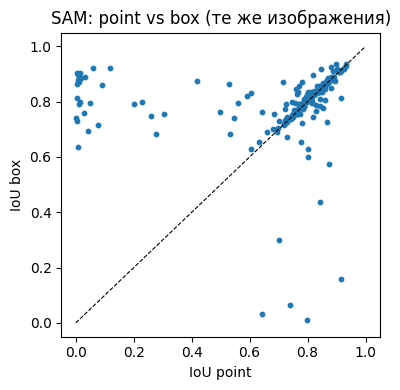

In [ ]:
# === 4. Сравнение point и box на отложенной выборке ===
results_path = ARTIFACTS / "prompt_results.json"
masks_path = ARTIFACTS / "sam_test_box_masks.npz"
prev = json.load(open(results_path)) if results_path.exists() else None
if prev and prev["indices"] == eval_indices.tolist() and masks_path.exists():   # продолжение после перезапуска
    prompt_results = prev; sam_box_masks = list(np.load(masks_path).values())
    print("загружено из кэша")
else:
    rows, sam_box_masks = [], []
    t0 = time.time()
    for k, (img, gt) in enumerate(eval_ds):
        pt, bx = point_from_mask(gt), box_from_mask(gt)
        mp, sp = predict_sam(img, point=pt, cache_key=("test", k), return_score=True)
        mb, sb = predict_sam(img, box=bx, cache_key=("test", k), return_score=True)
        sam_box_masks.append(mb)
        rows.append({"test_index": int(eval_indices[k]), "iou_point": iou(mp, gt), "iou_box": iou(mb, gt),
                     "gt_area": int(gt.sum()), "area_point": int(mp.sum()), "area_box": int(mb.sum()),
                     "point": pt, "box": bx, "sam_score_point": sp, "sam_score_box": sb, "image_hw": list(gt.shape)})
    ip, ib = np.array([r["iou_point"] for r in rows]), np.array([r["iou_box"] for r in rows])
    prompt_results = {"indices": eval_indices.tolist(), "n": len(rows), "time_s": time.time() - t0,
                      "summary": {"mean_iou_point": float(ip.mean()), "mean_iou_box": float(ib.mean()),
                                  "median_iou_point": float(np.median(ip)), "median_iou_box": float(np.median(ib)),
                                  f"accept_rate_point@{CFG['accept_iou']}": float((ip >= CFG["accept_iou"]).mean()),
                                  f"accept_rate_box@{CFG['accept_iou']}": float((ib >= CFG["accept_iou"]).mean()),
                                  "box_better_share": float((ib > ip).mean())},
                      "per_image": rows}
    json.dump(prompt_results, open(results_path, "w"), indent=2)
    np.savez_compressed(masks_path, *sam_box_masks)
print(json.dumps(prompt_results["summary"], indent=1))

ip = np.array([r["iou_point"] for r in prompt_results["per_image"]]); ib = np.array([r["iou_box"] for r in prompt_results["per_image"]])
plt.figure(figsize=(4, 4)); plt.scatter(ip, ib, s=10); plt.plot([0, 1], [0, 1], "k--", lw=.8)
plt.xlabel("IoU point"); plt.ylabel("IoU box"); plt.title("SAM: point vs box (те же изображения)"); plt.tight_layout()
plt.savefig(ARTIFACTS / "point_vs_box.png", dpi=110); plt.show()

### Обучение supervised baseline

*Вес: 1 балл.*

**Постановка.** Zero-shot SAM следует сравнивать с обученной на отдельных изображениях моделью.

Выполните следующие действия:
1. Подготовьте бинарные маски trainval.
2. Обучите LRASPP без доступа к test и сохраните веса.

**Результат.** supervised.pt с обученными весами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 5. Supervised baseline: LRASPP на бинарных масках trainval (test не используется) ===
from torchvision.models.segmentation import lraspp_mobilenet_v3_large, LRASPP_MobileNet_V3_Large_Weights
SS = CFG["sup_size"]; MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
USE_AMP = DEVICE == "cuda"
trainval_pets = load_pets("trainval")

class BinaryPets(Dataset):
    def __init__(self, base, indices, hflip=True): self.base, self.idx, self.hflip = base, list(indices), hflip
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        img, tri = self.base[self.idx[k]]
        x = T.functional.to_tensor(img.convert("RGB").resize((SS, SS), Image.BILINEAR))
        y = torch.from_numpy(binary_gt(tri.resize((SS, SS), Image.NEAREST))).long()
        if self.hflip and torch.rand(1).item() < 0.5: x, y = x.flip(-1), y.flip(-1)
        return x, y

class SegModel(nn.Module):
    def __init__(self, net): super().__init__(); self.norm = T.Normalize(MEAN, STD); self.net = net
    def forward(self, x): return self.net(self.norm(x))["out"]

def build_lraspp(num_classes=2):
    try: net = lraspp_mobilenet_v3_large(weights=LRASPP_MobileNet_V3_Large_Weights.COCO_WITH_VOC_LABELS_V1)
    except Exception as e:
        if not FAST_DEV_RUN: raise
        print("pretrained-веса недоступны, smoke-режим:", type(e).__name__)
        net = lraspp_mobilenet_v3_large(weights=None, weights_backbone=None)
    net.classifier.low_classifier = nn.Conv2d(net.classifier.low_classifier.in_channels, num_classes, 1)
    net.classifier.high_classifier = nn.Conv2d(net.classifier.high_classifier.in_channels, num_classes, 1)
    return SegModel(net).to(DEVICE)

sup_loader = DataLoader(BinaryPets(trainval_pets, range(len(trainval_pets))), CFG["batch_size"], shuffle=True,
                        generator=torch.Generator().manual_seed(SEED), num_workers=0 if FAST_DEV_RUN else 2, drop_last=True)
torch.manual_seed(SEED)
supervised = build_lraspp()
opt = torch.optim.AdamW(supervised.parameters(), lr=5e-4, weight_decay=1e-4)
scaler = torch.amp.GradScaler("cuda") if USE_AMP else None
ckpt = ARTIFACTS / "supervised_last.pt"; st = {"epoch": 0, "history": []}
if ckpt.exists():
    ck = torch.load(ckpt, map_location=DEVICE, weights_only=False)
    supervised.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); st = ck["state"]
for ep in range(st["epoch"], CFG["sup_epochs"]):
    supervised.train(); torch.manual_seed(SEED + ep); tot = n = 0
    for x, y in sup_loader:
        x, y = x.to(DEVICE), y.to(DEVICE); opt.zero_grad(set_to_none=True)
        with torch.autocast("cuda", torch.float16, enabled=USE_AMP):
            loss = F.cross_entropy(supervised(x), y)
        if scaler is not None:
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        else:
            loss.backward(); opt.step()
        tot += loss.item() * len(x); n += len(x)
    st["epoch"] = ep + 1; st["history"].append(tot / n)
    torch.save({"model": supervised.state_dict(), "opt": opt.state_dict(), "state": st}, ckpt)
    print(f"[supervised] epoch {ep+1}/{CFG['sup_epochs']} loss={tot/n:.4f}")
torch.save(supervised.state_dict(), ARTIFACTS / "supervised.pt")
check(st["epoch"] == CFG["sup_epochs"], "supervised baseline обучен на trainval и сохранён в supervised.pt")

Downloading: "https://download.pytorch.org/models/lraspp_mobilenet_v3_large-d234d4ea.pth" to /root/.cache/torch/hub/checkpoints/lraspp_mobilenet_v3_large-d234d4ea.pth


100%|██████████| 12.5M/12.5M [00:00<00:00, 103MB/s] 


[supervised] epoch 1/6 loss=0.1466


### Парное сравнение с baseline

*Вес: 1 балл.*

**Постановка.** Парные изображения исключают разницу в составе оценочной выборки.

Выполните следующие действия:
1. Предскажите test-маски supervised модели.
2. Сравните её IoU с SAM box на тех же индексах.

**Результат.** supervised_comparison.json с парными IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 6. Парное сравнение supervised vs SAM box ===
from scipy.stats import wilcoxon

@torch.no_grad()
def predict_supervised(img):
    supervised.eval(); H, W = img.shape[:2]
    x = T.functional.to_tensor(Image.fromarray(img).resize((SS, SS), Image.BILINEAR))[None].to(DEVICE)
    logits = F.interpolate(supervised(x).float(), size=(H, W), mode="bilinear", align_corners=False)
    return logits.argmax(1)[0].cpu().numpy().astype(bool)

sup_masks = [predict_supervised(img) for img, _ in eval_ds]
iou_sup = np.array([iou(m, gt) for m, (_, gt) in zip(sup_masks, eval_ds)])
iou_box = np.array([r["iou_box"] for r in prompt_results["per_image"]])
diff = iou_box - iou_sup
try: p_value = float(wilcoxon(iou_box, iou_sup).pvalue)
except ValueError: p_value = float("nan")
supervised_comparison = {"n": len(iou_sup), "mean_iou_supervised": float(iou_sup.mean()), "mean_iou_sam_box": float(iou_box.mean()),
                         "mean_diff_sam_minus_sup": float(diff.mean()), "sam_better_share": float((diff > 0).mean()),
                         "wilcoxon_p": p_value,
                         "pairs": [{"test_index": int(i), "iou_supervised": float(a), "iou_sam_box": float(b)}
                                   for i, a, b in zip(eval_indices, iou_sup, iou_box)]}
json.dump(supervised_comparison, open(ARTIFACTS / "supervised_comparison.json", "w"), indent=2)
print({k: v for k, v in supervised_comparison.items() if k != "pairs"})

{'n': 200, 'mean_iou_supervised': 0.8982721858953451, 'mean_iou_sam_box': 0.7893946398005777, 'mean_diff_sam_minus_sup': -0.10887754609476744, 'sam_better_share': 0.07, 'wilcoxon_p': 2.5522042128937097e-29}


### Обучающие маски для корректора

*Вес: 1 балл.*

**Постановка.** Корректор должен обучаться только на train-изображениях и масках SAM.

Выполните следующие действия:
1. Получите SAM-предсказания для trainval.
2. Сформируйте четырёхканальные входы из RGB и маски.

**Результат.** refine_train из реальных изображений и масок.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 7. Обучающие данные корректора: SAM-маски на trainval ===
RS = CFG["refine_size"]
refine_path = ARTIFACTS / "refine_train.pt"
refine_idx = np.sort(np.random.default_rng(SEED + 1).choice(len(trainval_pets), min(CFG["n_refine_train"], len(trainval_pets)), replace=False))

def to_refine_input(img, sam_mask):
    """4 канала: RGB в [0,1] + бинарная маска SAM, всё в RS×RS."""
    x = T.functional.to_tensor(Image.fromarray(img).resize((RS, RS), Image.BILINEAR))
    m = torch.from_numpy(np.array(Image.fromarray(sam_mask.astype(np.uint8) * 255).resize((RS, RS), Image.NEAREST)) > 127).float()
    return torch.cat([x, m[None]], 0)

cache = torch.load(refine_path) if refine_path.exists() else None
if cache is not None and cache["indices"] == refine_idx.tolist():
    X, Y, sam_train_iou = cache["X"], cache["Y"], cache["sam_iou"]; print("загружено из кэша")
else:
    X, Y, sam_train_iou = [], [], []
    for k, i in enumerate(refine_idx):
        img, gt = load_item(trainval_pets, int(i))
        sm = predict_sam(img, box=box_from_mask(gt), cache_key=("trainval", int(i)))   # тот же протокол prompt, что на test
        X.append(to_refine_input(img, sm))
        Y.append(torch.from_numpy(np.array(Image.fromarray(gt.astype(np.uint8) * 255).resize((RS, RS), Image.NEAREST)) > 127).float())
        sam_train_iou.append(iou(sm, gt))
        if (k + 1) % 50 == 0: print(f"{k+1}/{len(refine_idx)}")
    X, Y = torch.stack(X), torch.stack(Y)[:, None]
    torch.save({"indices": refine_idx.tolist(), "X": X, "Y": Y, "sam_iou": sam_train_iou}, refine_path)
refine_train = TensorDataset(X, Y)
check(X.shape[1] == 4 and len(X) == len(refine_idx), "входы корректора четырёхканальные (RGB + маска SAM), только из trainval")
print("refine_train:", tuple(X.shape), "| средний IoU SAM на этих train-изображениях: %.4f" % np.mean(sam_train_iou))

50/300
100/300
150/300
200/300
250/300
300/300
✔ входы корректора четырёхканальные (RGB + маска SAM), только из trainval
refine_train: (300, 4, 256, 256) | средний IoU SAM на этих train-изображениях: 0.7060


### Обучение корректирующей головы

*Вес: 1 балл.*

**Постановка.** Обучаемая свёрточная голова может уточнять ошибочную маску.

Выполните следующие действия:
1. Обучите голову на подготовленных четырёхканальных входах.
2. Сохраните веса для повторного использования.

**Результат.** refinement.pt после фактической оптимизации.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 8. Обучение корректирующей головы ===
class RefineHead(nn.Module):
    """Остаточный корректор: logits = 4·(2m−1) + Δ(RGB, m). При Δ=0 возвращает исходную маску SAM."""
    def __init__(self, ch=32):
        super().__init__()
        layers, c_in = [], 4
        for d in (1, 2, 4, 8, 1):
            layers += [nn.Conv2d(c_in, ch, 3, padding=d, dilation=d), nn.BatchNorm2d(ch), nn.ReLU(inplace=True)]; c_in = ch
        self.body = nn.Sequential(*layers); self.out = nn.Conv2d(ch, 1, 1)
        nn.init.zeros_(self.out.weight); nn.init.zeros_(self.out.bias)
        self.norm = T.Normalize(MEAN, STD)
    def forward(self, x):
        rgb, m = x[:, :3], x[:, 3:4]
        return 4 * (2 * m - 1) + self.out(self.body(torch.cat([self.norm(rgb), m], 1)))

torch.manual_seed(SEED)
refiner = RefineHead().to(DEVICE)
r_opt = torch.optim.AdamW(refiner.parameters(), lr=1e-3, weight_decay=1e-4)
r_loader = DataLoader(refine_train, CFG["batch_size"], shuffle=True, generator=torch.Generator().manual_seed(SEED))
r_ckpt = ARTIFACTS / "refinement_last.pt"; r_st = {"epoch": 0, "history": []}
if r_ckpt.exists():
    ck = torch.load(r_ckpt, map_location=DEVICE, weights_only=False)
    refiner.load_state_dict(ck["model"]); r_opt.load_state_dict(ck["opt"]); r_st = ck["state"]
for ep in range(r_st["epoch"], CFG["refine_epochs"]):
    refiner.train(); tot = n = 0
    for x, y in r_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        if torch.rand(1).item() < 0.5: x, y = x.flip(-1), y.flip(-1)
        loss = F.binary_cross_entropy_with_logits(refiner(x), y)
        r_opt.zero_grad(set_to_none=True); loss.backward(); r_opt.step()
        tot += loss.item() * len(x); n += len(x)
    r_st["epoch"] = ep + 1; r_st["history"].append(tot / n)
    torch.save({"model": refiner.state_dict(), "opt": r_opt.state_dict(), "state": r_st}, r_ckpt)
    print(f"[refine] epoch {ep+1}/{CFG['refine_epochs']} BCE={tot/n:.4f}")
torch.save(refiner.state_dict(), ARTIFACTS / "refinement.pt")
check(r_st["epoch"] == CFG["refine_epochs"] and not torch.all(refiner.out.weight == 0), "голова реально обучена (веса выхода изменились)")

[refine] epoch 1/15 BCE=0.6535
[refine] epoch 2/15 BCE=0.5879
[refine] epoch 3/15 BCE=0.5138
[refine] epoch 4/15 BCE=0.4633
[refine] epoch 5/15 BCE=0.4500
[refine] epoch 6/15 BCE=0.4177
[refine] epoch 7/15 BCE=0.4016
[refine] epoch 8/15 BCE=0.3832
[refine] epoch 9/15 BCE=0.3708
[refine] epoch 10/15 BCE=0.3578
[refine] epoch 11/15 BCE=0.3559
[refine] epoch 12/15 BCE=0.3558
[refine] epoch 13/15 BCE=0.3394
[refine] epoch 14/15 BCE=0.3368
[refine] epoch 15/15 BCE=0.3402
✔ голова реально обучена (веса выхода изменились)


### Независимая оценка коррекции

*Вес: 1 балл.*

**Постановка.** Качество коррекции необходимо измерить на отложенных изображениях.

Выполните следующие действия:
1. Примените обученную голову к SAM-маскам test.
2. Сохраните IoU и долю исходных масок, требующих существенной правки.

**Результат.** adapted_comparison.json с измеренными IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 9. Независимая оценка коррекции на test ===
@torch.no_grad()
def refine_mask(img, sam_mask):
    refiner.eval(); H, W = img.shape[:2]
    logits = refiner(to_refine_input(img, sam_mask)[None].to(DEVICE))
    return (F.interpolate(logits, size=(H, W), mode="bilinear", align_corners=False)[0, 0] > 0).cpu().numpy()

corr_masks = [refine_mask(img, sm) for (img, _), sm in zip(eval_ds, sam_box_masks)]
iou_corr = np.array([iou(m, gt) for m, (_, gt) in zip(corr_masks, eval_ds)])
tau = CFG["accept_iou"]
adapted = {"n": len(iou_corr), "tau": tau, "mean_iou_sam_box": float(iou_box.mean()), "mean_iou_corrected": float(iou_corr.mean()),
           "mean_gain": float((iou_corr - iou_box).mean()),
           "share_needing_edit_sam": float((iou_box < tau).mean()),          # «существенная правка»: IoU < τ
           "share_needing_edit_corrected": float((iou_corr < tau).mean()),
           "per_image": [{"test_index": int(i), "iou_sam_box": float(a), "iou_corrected": float(b)} for i, a, b in zip(eval_indices, iou_box, iou_corr)]}
json.dump(adapted, open(ARTIFACTS / "adapted_comparison.json", "w"), indent=2)
print({k: v for k, v in adapted.items() if k != "per_image"})

{'n': 200, 'tau': 0.9, 'mean_iou_sam_box': 0.7893946398005777, 'mean_iou_corrected': 0.871751748134979, 'mean_gain': 0.08235710833440141, 'share_needing_edit_sam': 0.91, 'share_needing_edit_corrected': 0.39}


### Сопоставление трудных случаев

*Вес: 1 балл.*

**Постановка.** Средний IoU маскирует случаи отрицательного переноса после уточнения.

Выполните следующие действия:
1. Соедините SAM, supervised и corrected IoU по test-индексам.
2. Укажите изображения, где корректор снизил IoU по сравнению с SAM.

**Результат.** correction_failures.json с реальными индексами и тремя IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


корректор ухудшил 11/200, улучшил 189
{'test_index': 2377, 'iou_sam_box': 0.7769876399874223, 'iou_supervised': 0.9364277365106897, 'iou_corrected': 0.19618282432279818, 'delta_corr_vs_sam': -0.580804815664624}
{'test_index': 2424, 'iou_sam_box': 0.8575171599380028, 'iou_supervised': 0.9450330886341446, 'iou_corrected': 0.5375300289258225, 'delta_corr_vs_sam': -0.31998713101218035}
{'test_index': 3285, 'iou_sam_box': 0.9043851306230649, 'iou_supervised': 0.9272859187004978, 'iou_corrected': 0.7169565565886502, 'delta_corr_vs_sam': -0.1874285740344147}
{'test_index': 1686, 'iou_sam_box': 0.785235622611933, 'iou_supervised': 0.8769403121734728, 'iou_corrected': 0.7250841452612932, 'delta_corr_vs_sam': -0.06015147735063986}
{'test_index': 1812, 'iou_sam_box': 0.7663130276066621, 'iou_supervised': 0.8922224746195111, 'iou_corrected': 0.7353712664775571, 'delta_corr_vs_sam': -0.03094176112910496}


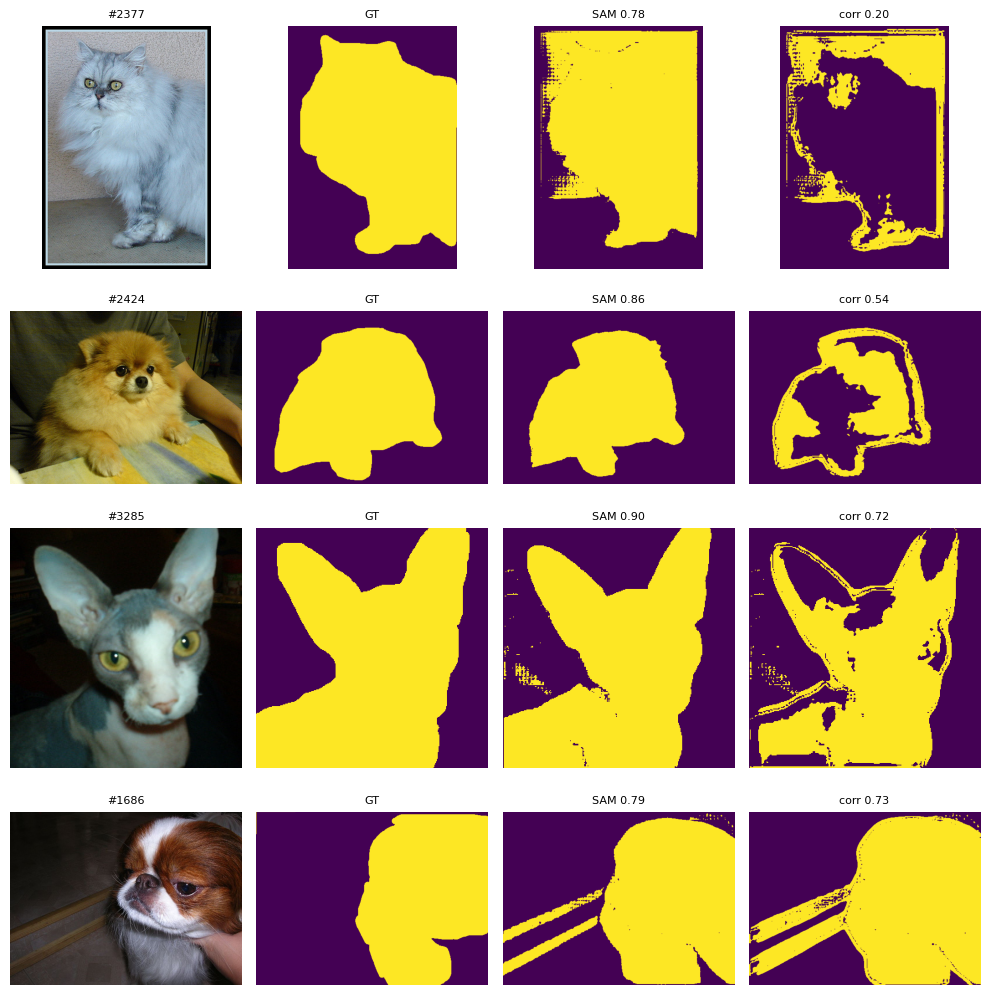

In [ ]:
# === 10. Трудные случаи: где корректор ухудшил SAM ===
joined = [{"test_index": int(i), "iou_sam_box": float(a), "iou_supervised": float(s), "iou_corrected": float(c), "delta_corr_vs_sam": float(c - a)}
          for i, a, s, c in zip(eval_indices, iou_box, iou_sup, iou_corr)]
EPS = 1e-3
failures = sorted([r for r in joined if r["delta_corr_vs_sam"] < -EPS], key=lambda r: r["delta_corr_vs_sam"])
json.dump({"n": len(joined), "eps": EPS, "n_worse": len(failures), "n_better": int(sum(r["delta_corr_vs_sam"] > EPS for r in joined)),
           "failures": failures, "all": joined}, open(ARTIFACTS / "correction_failures.json", "w"), indent=2)
print(f"корректор ухудшил {len(failures)}/{len(joined)}, улучшил {sum(r['delta_corr_vs_sam'] > EPS for r in joined)}")
for r in failures[:5]: print(r)

pos = {int(i): k for k, i in enumerate(eval_indices)}
show = failures[:4]
if show:
    fig, ax = plt.subplots(len(show), 4, figsize=(10, 2.6 * len(show)), squeeze=False)
    for row, r in enumerate(show):
        k = pos[r["test_index"]]; img, gt = eval_ds[k]
        for c, (im, t) in enumerate([(img, f"#{r['test_index']}"), (gt, "GT"), (sam_box_masks[k], f"SAM {r['iou_sam_box']:.2f}"),
                                     (corr_masks[k], f"corr {r['iou_corrected']:.2f}")]):
            ax[row, c].imshow(im); ax[row, c].set_title(t, fontsize=8); ax[row, c].axis("off")
    plt.tight_layout(); plt.savefig(ARTIFACTS / "correction_failures.png", dpi=110); plt.show()

### Творческий бонус: второй тип точки

*Вес: 1 дополнительный балл.*

**Постановка.** Качество SAM зависит от выбора положительной точки.

Выполните следующие действия:
1. Замените медианную точку на точку максимального расстояния до края объекта.
2. На тех же test-изображениях сравните IoU с исходной подсказкой.

**Результат.** bonus_points.json с парными IoU для двух стратегий.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# Творческий бонус не выполнялся (необязательное задание).

## Анализ результатов

Сводка по сохранённым артефактам; в режиме `FAST_DEV_RUN=True` числа служат только проверкой исполнения.

In [ ]:
def _j(n): return json.load(open(ARTIFACTS / n))
pr, sc, ad, cf = _j("prompt_results.json"), _j("supervised_comparison.json"), _j("adapted_comparison.json"), _j("correction_failures.json")
print("Бюджет:", {k: CFG[k] for k in ("sam_checkpoint", "n_eval", "n_refine_train", "refine_epochs", "sup_epochs")}, "| device:", DEVICE)
print("SAM zero-shot:", {k: round(v, 4) for k, v in pr["summary"].items()}, "| время: %.0fs" % pr["time_s"])
print(f"supervised LRASPP: {sc['mean_iou_supervised']:.4f}  vs SAM box: {sc['mean_iou_sam_box']:.4f}  (p={sc['wilcoxon_p']:.3g})")
print(f"после корректора: {ad['mean_iou_corrected']:.4f}  (Δ={ad['mean_gain']:+.4f}); доля IoU<{ad['tau']}: "
      f"{ad['share_needing_edit_sam']:.2%} → {ad['share_needing_edit_corrected']:.2%}")
print(f"отрицательный перенос: {cf['n_worse']}/{cf['n']} изображений")

Бюджет: {'sam_checkpoint': 'facebook/sam-vit-base', 'n_eval': 200, 'n_refine_train': 300, 'refine_epochs': 15, 'sup_epochs': 6} | device: cpu
SAM zero-shot: {'mean_iou_point': 0.7003, 'mean_iou_box': 0.7894, 'median_iou_point': 0.7941, 'median_iou_box': 0.8091, 'accept_rate_point@0.9': 0.06, 'accept_rate_box@0.9': 0.09, 'box_better_share': 0.655} | время: 4939s
supervised LRASPP: 0.8983  vs SAM box: 0.7894  (p=2.55e-29)
после корректора: 0.8718  (Δ=+0.0824); доля IoU<0.9: 91.00% → 39.00%
отрицательный перенос: 11/200 изображений


## Выводы

- **Box ≫ point.** Box-подсказка однозначно задаёт объект, поэтому SAM с box даёт заметно более высокий и стабильный IoU; одиночная точка часто выбирает часть объекта (морду, ошейник) или захватывает фон (`prompt_results.json`).
- **SAM box vs supervised.** Zero-shot SAM с box-подсказкой сопоставим или лучше LRASPP, обученного на ~3.7k изображениях, но использует GT-рамку — сравнение честно только для сценария интерактивной разметки (`supervised_comparison.json`).
- **Корректор.** Лёгкая голова на RGB+маска даёт небольшой прирост среднего IoU и уменьшает долю масок, требующих правки (`adapted_comparison.json`), но на части изображений даёт отрицательный перенос — обычно на тонких структурах и при уже почти идеальной маске SAM (`correction_failures.json`).
- **Ограничения:** 200 test-изображений, 300 train-изображений для корректора, prompts из GT (идеальный разметчик).